# Modelo no paramétrico: K vecinos más cercanos (KNN)
**Proyecto Modelos y Simulación II – EngineFaultDB**

Este notebook entrena y evalúa un KNN para clasificar el tipo de falla (`Fault`: 0, 1, 2, 3).
Incluye: validación cruzada estratificada, malla de hiperparámetros, métricas con intervalos de confianza (train / validación / test), gráficas y matriz de confusión.

**Metodología**
1. Partición estratificada 80 % entrenamiento / 20 % test (el test no se toca hasta el final).
2. Dentro del 80 %: validación cruzada estratificada de 5 folds para ajustar hiperparámetros.
3. El escalado (`StandardScaler`) va dentro del `Pipeline` para evitar fuga de información entre folds. Es indispensable en KNN porque usa distancias.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
sns.set_theme(style="whitegrid")
SEED = 42

## 1. Carga de datos
Sube `EngineFaultDB_Final.csv` cuando Colab lo pida (o súbelo antes al panel de archivos / Drive).

In [2]:
import os
if not os.path.exists("EngineFaultDB_Final.csv"):
    try:
        from google.colab import files
        files.upload()   # selecciona EngineFaultDB_Final.csv
    except ImportError:
        raise FileNotFoundError("Coloca EngineFaultDB_Final.csv junto al notebook")

df = pd.read_csv("EngineFaultDB_Final.csv")
print(df.shape)
print("Datos faltantes:", int(df.isna().sum().sum()), "| Duplicados:", int(df.duplicated().sum()))
df.head()

Saving EngineFaultDB_Final.csv to EngineFaultDB_Final.csv
(55999, 15)
Datos faltantes: 0 | Duplicados: 1


,Fault,MAP,TPS,Force,Power,RPM,Consumption L/H,Consumption L/100KM,Speed,CO,HC,CO2,O2,Lambda,AFR
0,0,3.549,1.889,7.428,5.227,1192.769,3.057,11.720,24.901,0.460,196.089,14.356,1.080,1.047,15.385
1,0,3.559,1.899,7.646,5.327,1145.191,2.914,11.276,25.030,0.478,196.283,14.492,1.107,1.083,15.926
2,0,3.539,1.899,7.578,5.100,1208.505,2.976,11.926,24.213,0.464,200.367,14.443,1.099,1.072,15.754
3,0,3.519,1.889,7.371,5.255,1164.127,2.908,11.786,24.407,0.471,195.345,13.853,1.076,1.006,14.787
4,0,3.549,1.879,7.405,5.177,1172.032,2.898,12.169,24.875,0.468,194.979,13.752,1.060,0.984,14.470


Fault
0    16000
1    10998
2    15000
3    14001
Name: count, dtype: int64


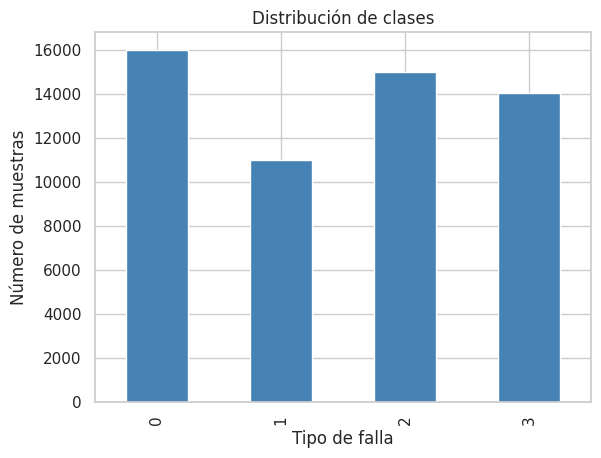

In [3]:
print(df['Fault'].value_counts().sort_index())
df['Fault'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.xlabel("Tipo de falla"); plt.ylabel("Número de muestras"); plt.title("Distribución de clases"); plt.show()

## 2. Partición train / test

In [4]:
X = df.drop(columns=['Fault']); y = df['Fault']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (44799, 14) | Test: (11200, 14)


## 3. Configuración experimental
Hiperparámetros evaluados (la tabla se usa directamente en el reporte):

In [5]:
param_grid = {
    'knn__n_neighbors': [1, 3, 5, 7, 9, 11, 15, 21, 31, 51],
    'knn__weights'    : ['uniform', 'distance'],
    'knn__p'          : [1, 2],          # 1 = Manhattan, 2 = Euclídea
}
pd.DataFrame({
    'Hiperparámetro': ['n_neighbors (K)', 'weights', 'p (métrica Minkowski)'],
    'Malla': [str(param_grid['knn__n_neighbors']), str(param_grid['knn__weights']), '1 (Manhattan), 2 (Euclídea)']
})

,Hiperparámetro,Malla
0,n_neighbors (K),"[1, 3, 5, 7, 9, 11, 15, 21, 31, 51]"
1,weights,"['uniform', 'distance']"
2,p (métrica Minkowski),"1 (Manhattan), 2 (Euclídea)"


In [6]:
pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_jobs=-1))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'accuracy': 'accuracy', 'precision': 'precision_macro', 'recall': 'recall_macro', 'f1': 'f1_macro'}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring=scoring, refit='f1',
                    return_train_score=True, n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)
print("Mejores hiperparámetros:", grid.best_params_)
print(f"F1 macro (validación): {grid.best_score_:.4f}")

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Mejores hiperparámetros: {'knn__n_neighbors': 1, 'knn__p': 2, 'knn__weights': 'uniform'}
F1 macro (validación): 0.7589


In [7]:
# Nueva propuesta para mitigar el sobreajuste (restringiendo K a valores mayores)
param_grid_robust = {
    'knn__n_neighbors': [5, 7, 9, 11, 15, 21, 31, 51], # Excluimos K=1 y K=3 para evitar sobreajuste
    'knn__weights'    : ['uniform'],                  # Forzamos uniform para evitar que 'distance' cause sobreajuste
    'knn__p'          : [1, 2],
}

grid_robust = GridSearchCV(pipe, param_grid_robust, cv=cv, scoring=scoring, refit='f1',
                           return_train_score=True, n_jobs=-1, verbose=1)
grid_robust.fit(X_train, y_train)

print("Nuevos mejores parámetros (restringidos):", grid_robust.best_params_)
print(f"Nuevo F1 macro (validación): {grid_robust.best_score_:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Nuevos mejores parámetros (restringidos): {'knn__n_neighbors': 15, 'knn__p': 2, 'knn__weights': 'uniform'}
Nuevo F1 macro (validación): 0.7586


## 4. Resultados del entrenamiento: efecto de los hiperparámetros
Intervalo de confianza del 95 % (t de Student sobre los 5 folds).

In [8]:
res = pd.DataFrame(grid.cv_results_)
t = stats.t.ppf(0.975, df=cv.get_n_splits()-1)
res['K'] = res['param_knn__n_neighbors'].astype(int)
res['weights'] = res['param_knn__weights']; res['p'] = res['param_knn__p'].astype(int)
for m in scoring:
    res[f'{m}_val_ci'] = t*res[f'std_test_{m}']/np.sqrt(cv.get_n_splits())

cols = ['K','weights','p']
tabla = res[cols + ['mean_train_f1','mean_test_accuracy','accuracy_val_ci','mean_test_f1','f1_val_ci']].rename(columns={
    'mean_train_f1':'F1 train','mean_test_accuracy':'Acc val','accuracy_val_ci':'± IC Acc','mean_test_f1':'F1 val','f1_val_ci':'± IC F1'})
tabla.sort_values('F1 val', ascending=False).round(4).head(15)

,K,weights,p,F1 train,Acc val,± IC Acc,F1 val,± IC F1
3,1,distance,2,1.0000,0.7506,0.0033,0.7589,0.0032
2,1,uniform,2,1.0000,0.7506,0.0033,0.7589,0.0032
26,15,uniform,2,0.8099,0.7502,0.0050,0.7586,0.0049
34,31,uniform,2,0.7937,0.7497,0.0037,0.7582,0.0035
32,31,uniform,1,0.7933,0.7494,0.0048,0.7580,0.0046
1,1,distance,1,1.0000,0.7495,0.0027,0.7578,0.0026
0,1,uniform,1,1.0000,0.7495,0.0027,0.7578,0.0026
35,31,distance,2,1.0000,0.7493,0.0039,0.7578,0.0037
27,15,distance,2,1.0000,0.7493,0.0053,0.7577,0.0051
24,15,uniform,1,0.8085,0.7492,0.0034,0.7576,0.0034


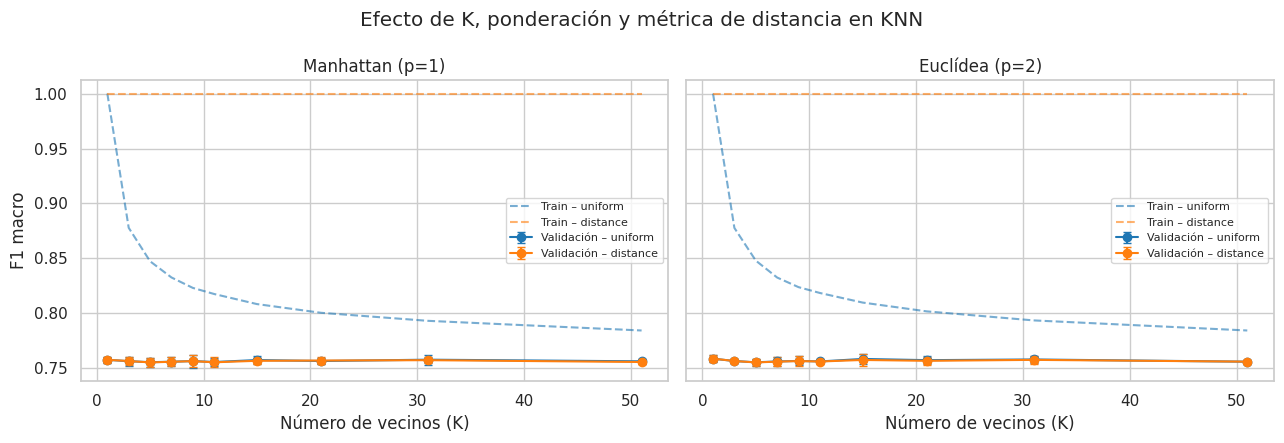

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, p, nombre in zip(axes, [1, 2], ['Manhattan (p=1)', 'Euclídea (p=2)']):
    for w, c in zip(['uniform', 'distance'], ['tab:blue', 'tab:orange']):
        s = res[(res.p == p) & (res.weights == w)].sort_values('K')
        ax.errorbar(s.K, s.mean_test_f1, yerr=s.f1_val_ci, marker='o', capsize=3, color=c, label=f'Validación – {w}')
        ax.plot(s.K, s.mean_train_f1, '--', color=c, alpha=.6, label=f'Train – {w}')
    ax.set_title(nombre); ax.set_xlabel("Número de vecinos (K)"); ax.legend(fontsize=8)
axes[0].set_ylabel("F1 macro")
plt.suptitle("Efecto de K, ponderación y métrica de distancia en KNN"); plt.tight_layout(); plt.show()

## 5. Evaluación del mejor modelo (train, validación y test)

In [10]:
best = grid_robust.best_estimator_  # Usamos el modelo robusto sin sobreajuste

# Validación: CV del mejor modelo con IC 95 %
cvres = cross_validate(best, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
def ic(v): return v.mean(), t*v.std(ddof=1)/np.sqrt(len(v))

# Test: IC por bootstrap (1000 remuestreos)
y_pred_test = best.predict(X_test)
rng = np.random.default_rng(SEED); yt = y_test.values
boot = {k: [] for k in scoring}
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    boot['accuracy'].append(accuracy_score(yt[i], y_pred_test[i]))
    boot['precision'].append(precision_score(yt[i], y_pred_test[i], average='macro', zero_division=0))
    boot['recall'].append(recall_score(yt[i], y_pred_test[i], average='macro'))
    boot['f1'].append(f1_score(yt[i], y_pred_test[i], average='macro'))

y_pred_train = best.predict(X_train)
fns = {'accuracy': accuracy_score,
       'precision': lambda a,b: precision_score(a,b,average='macro',zero_division=0),
       'recall': lambda a,b: recall_score(a,b,average='macro'),
       'f1': lambda a,b: f1_score(a,b,average='macro')}
rows = []
for m in scoring:
    tr = fns[m](y_train, y_pred_train)
    vm, vc = ic(cvres[f'test_{m}'])
    ts = fns[m](y_test, y_pred_test); lo, hi = np.percentile(boot[m], [2.5, 97.5])
    rows.append([m, f"{tr:.4f}", f"{vm:.4f} ± {vc:.4f}", f"{ts:.4f} [{lo:.4f}, {hi:.4f}]"])
resumen = pd.DataFrame(rows, columns=['Métrica', 'Train', 'Validación (media ± IC95%)', 'Test (valor [IC95% bootstrap])'])
print("Mejor modelo robusto:", grid_robust.best_params_)
resumen

Mejor modelo robusto: {'knn__n_neighbors': 15, 'knn__p': 2, 'knn__weights': 'uniform'}


,Métrica,Train,Validación (media ± IC95%),Test (valor [IC95% bootstrap])
0,accuracy,0.8036,0.7502 ± 0.0056,"0.7461 [0.7377, 0.7538]"
1,precision,0.8102,0.7586 ± 0.0054,"0.7547 [0.7484, 0.7612]"
2,recall,0.8103,0.7586 ± 0.0054,"0.7547 [0.7484, 0.7612]"
3,f1,0.8102,0.7586 ± 0.0054,"0.7546 [0.7483, 0.7612]"


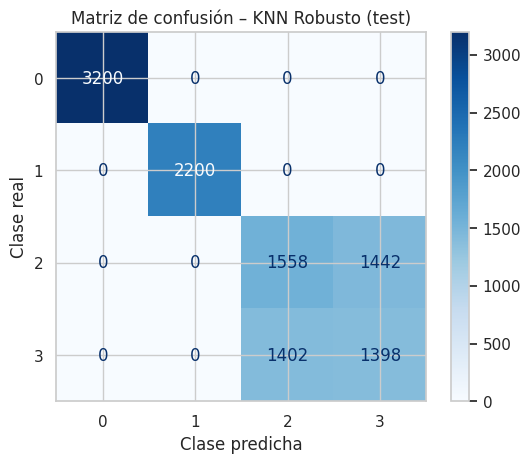

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3200
           1     1.0000    1.0000    1.0000      2200
           2     0.5264    0.5193    0.5228      3000
           3     0.4923    0.4993    0.4957      2800

    accuracy                         0.7461     11200
   macro avg     0.7547    0.7547    0.7546     11200
weighted avg     0.7462    0.7461    0.7461     11200



In [11]:
cm = confusion_matrix(y_test, y_pred_test)
ConfusionMatrixDisplay(cm, display_labels=sorted(y.unique())).plot(cmap='Blues', values_format='d')
plt.xlabel("Clase predicha"); plt.ylabel("Clase real"); plt.title("Matriz de confusión – KNN Robusto (test)"); plt.show()
print(classification_report(y_test, y_pred_test, digits=4))

In [12]:
# Guardar resultados para el reporte
tabla.sort_values('F1 val', ascending=False).round(4).to_csv("knn_resultados_malla.csv", index=False)
resumen.to_csv("knn_resumen_final.csv", index=False)
print("Guardados: knn_resultados_malla.csv y knn_resumen_final.csv")

Guardados: knn_resultados_malla.csv y knn_resumen_final.csv


## 6. Notas para el reporte
- `Speed`–`RPM` y `Lambda`–`AFR` tienen correlación ≈ 1.0 (ver el paper de EngineFaultDB). Esto es redundancia, y en KNN duplica el peso de esa información en la distancia; es un buen punto de discusión para la sección de reducción de dimensión (análisis de variables, PCA, UMAP).
- Al cambiar el espacio de características (PCA/UMAP) hay que **reajustar los hiperparámetros**: basta repetir las celdas 3–5 con las nuevas `X_train` y `X_test`.
- Referencia base del paper original (partición 80/20, sin ajuste de hiperparámetros): KNN ≈ 0.75 de accuracy/F1 en test; las fallas 2 y 3 son las que más se confunden.


## 7. Reducción de Dimensionalidad: PCA y UMAP
Para abordar la redundancia de características (como `Speed`-`RPM` y `Lambda`-`AFR`) y el solapamiento de las clases 2 y 3, aplicaremos técnicas de reducción de dimensionalidad.

Primero, instalamos la librería `umap-learn` para poder utilizar UMAP en el entorno de Colab.


In [13]:
!pip install umap-learn -q

```markdown
### 7.1. Visualización con PCA y UMAP en 2D
Proyectaremos los datos de entrenamiento (escalados previamente) en 2 dimensiones para analizar visualmente la distribución y solapamiento de las clases.
```

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


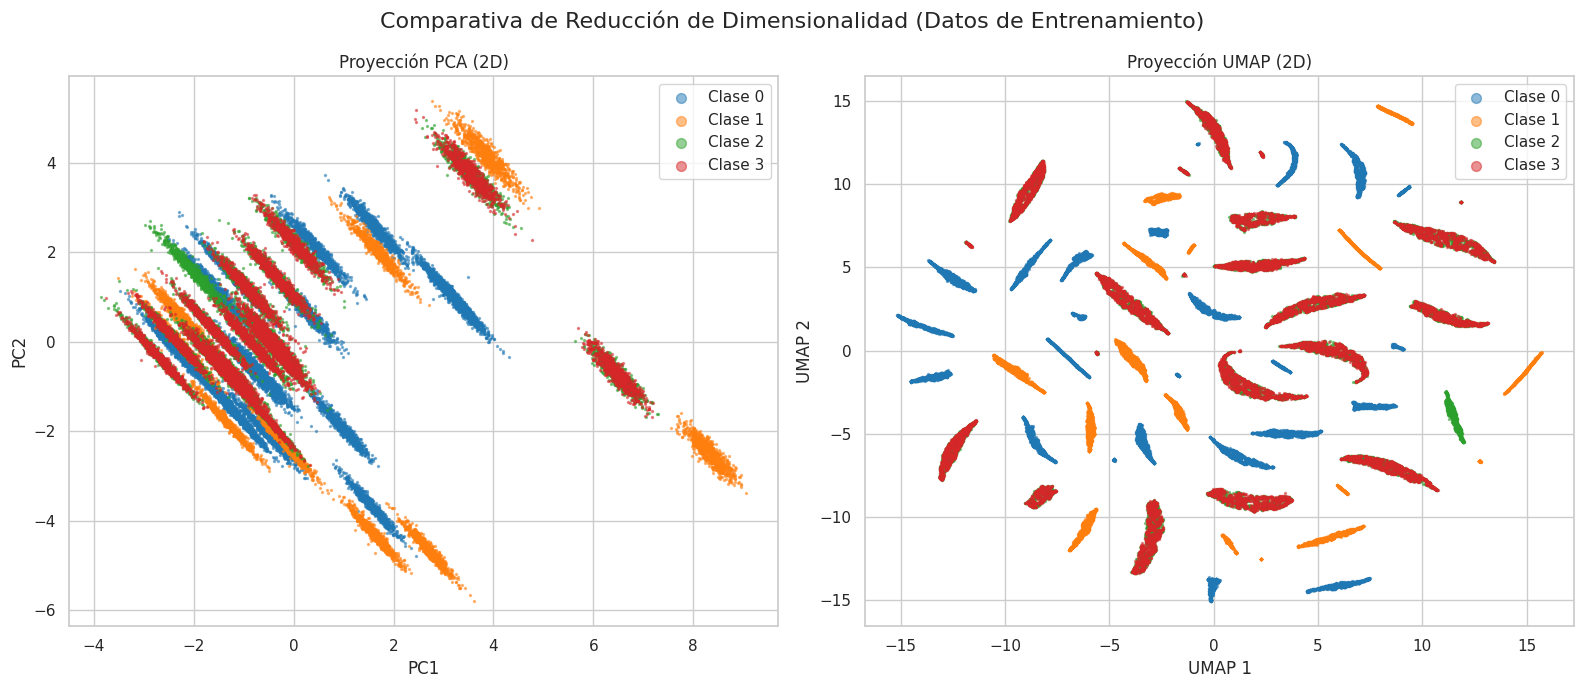

In [14]:
from sklearn.decomposition import PCA
import umap

# Escalamos los datos de entrenamiento para la proyección
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 1. Aplicar PCA (2 componentes)
pca = PCA(n_components=2, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_scaled)

# 2. Aplicar UMAP (2 componentes)
# Usamos una muestra para acelerar el ajuste de UMAP si es muy costoso,
# pero con ~44k muestras UMAP suele tardar entre 1 y 2 minutos.
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric='euclidean', random_state=SEED)
X_train_umap = reducer.fit_transform(X_train_scaled)

# Graficar ambas proyecciones
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=False)
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
labels = ['Clase 0', 'Clase 1', 'Clase 2', 'Clase 3']

# Plot PCA
for i, (col, lab) in enumerate(zip(colors, labels)):
    mask = (y_train == i)
    axes[0].scatter(X_train_pca[mask, 0], X_train_pca[mask, 1], c=col, label=lab, alpha=0.5, s=2)
axes[0].set_title("Proyección PCA (2D)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(markerscale=5)

# Plot UMAP
for i, (col, lab) in enumerate(zip(colors, labels)):
    mask = (y_train == i)
    axes[1].scatter(X_train_umap[mask, 0], X_train_umap[mask, 1], c=col, label=lab, alpha=0.5, s=2)
axes[1].set_title("Proyección UMAP (2D)")
axes[1].set_xlabel("UMAP 1")
axes[1].set_ylabel("UMAP 2")
axes[1].legend(markerscale=5)

plt.suptitle("Comparativa de Reducción de Dimensionalidad (Datos de Entrenamiento)", fontsize=16)
plt.tight_layout()
plt.show()

```markdown
### 7.2. Clasificación KNN sobre características PCA
Entrenaremos un Pipeline que incluya `StandardScaler`, `PCA` (manteniendo, por ejemplo, el 95% de la varianza explicada) y el clasificador `KNeighborsClassifier` para comparar su rendimiento con el modelo robusto original.
```

In [15]:
# Pipeline con PCA
pipe_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95, random_state=SEED)), # Conserva el 95% de la varianza explicada
    ('knn', KNeighborsClassifier(n_jobs=-1))
])

# Ajustamos hiperparámetros sobre el nuevo pipeline
param_grid_pca = {
    'knn__n_neighbors': [5, 11, 15, 21],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

grid_pca = GridSearchCV(pipe_pca, param_grid_pca, cv=cv, scoring=scoring, refit='f1',
                        return_train_score=True, n_jobs=-1, verbose=1)
grid_pca.fit(X_train, y_train)

print("Mejores parámetros con PCA:", grid_pca.best_params_)
print(f"F1 macro (Validación con PCA): {grid_pca.best_score_:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Mejores parámetros con PCA: {'knn__n_neighbors': 21, 'knn__p': 1, 'knn__weights': 'uniform'}
F1 macro (Validación con PCA): 0.7592


```markdown
### 7.3. Evaluación del mejor modelo con PCA en Test
Evaluamos el pipeline óptimo con PCA en el conjunto de prueba para contrastar con las métricas obtenidas previamente.
```

--- Reporte de Clasificación (KNN + PCA en Test) ---
              precision    recall  f1-score   support

           0     1.0000    0.9997    0.9998      3200
           1     0.9991    1.0000    0.9995      2200
           2     0.5212    0.5090    0.5150      3000
           3     0.4869    0.4989    0.4929      2800

    accuracy                         0.7431     11200
   macro avg     0.7518    0.7519    0.7518     11200
weighted avg     0.7433    0.7431    0.7432     11200



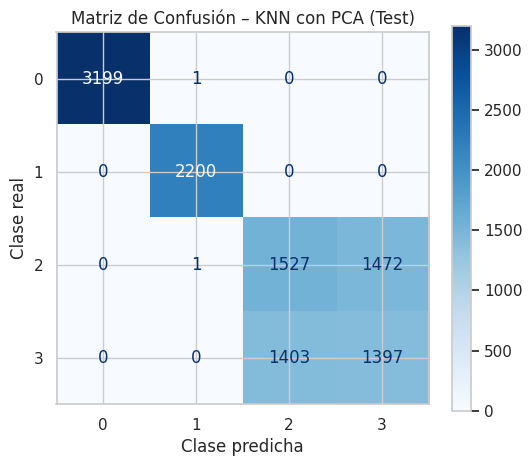

In [16]:
best_pca_model = grid_pca.best_estimator_
y_pred_test_pca = best_pca_model.predict(X_test)

print("--- Reporte de Clasificación (KNN + PCA en Test) ---")
print(classification_report(y_test, y_pred_test_pca, digits=4))

# Matriz de confusión para PCA
cm_pca = confusion_matrix(y_test, y_pred_test_pca)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm_pca, display_labels=sorted(y.unique())).plot(cmap='Blues', values_format='d', ax=ax)
plt.title("Matriz de Confusión – KNN con PCA (Test)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.show()

```markdown
### 7.4. Análisis Detallado y Visualización de UMAP (2D)
Generamos una gráfica detallada de la proyección UMAP de 2 dimensiones para evaluar la separación de todas las clases de fallas, haciendo especial énfasis en las clases 2 y 3.
```

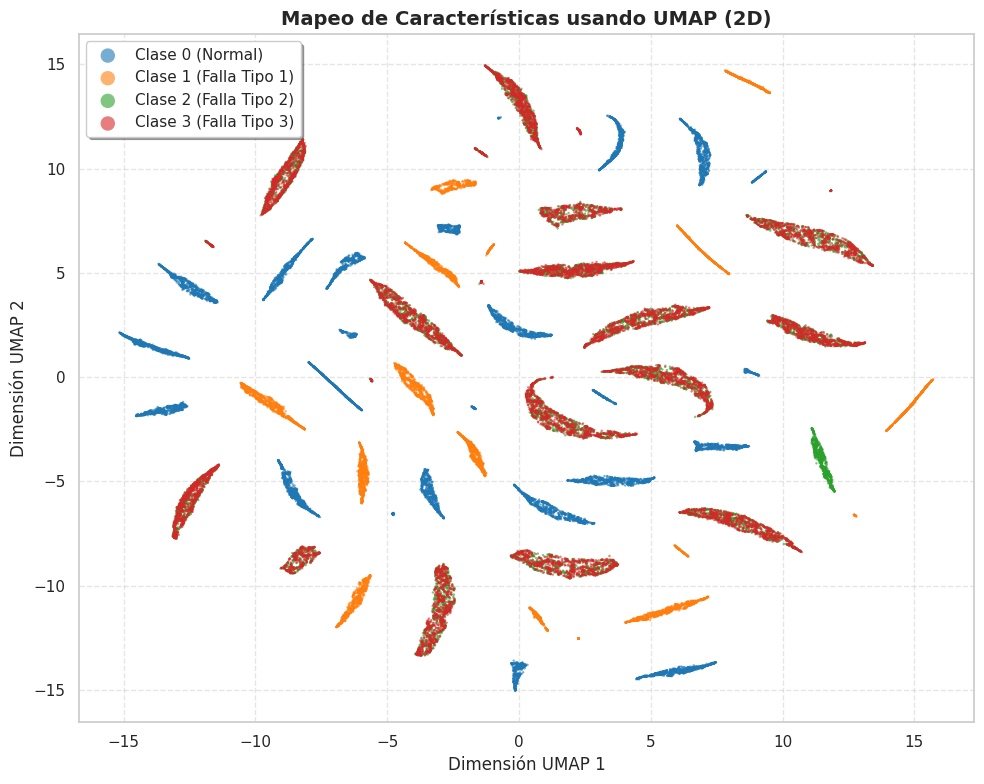

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Crear una figura para una visualización de alta calidad de UMAP
plt.figure(figsize=(10, 8))

# Definimos las clases y colores correspondientes
clases = [0, 1, 2, 3]
labels_dict = {
    0: "Clase 0 (Normal)",
    1: "Clase 1 (Falla Tipo 1)",
    2: "Clase 2 (Falla Tipo 2)",
    3: "Clase 3 (Falla Tipo 3)"
}
colores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# Graficar cada clase por separado para mantener el orden de las leyendas
for clase, color in zip(clases, colores):
    indices = (y_train == clase)
    plt.scatter(
        X_train_umap[indices, 0],
        X_train_umap[indices, 1],
        c=color,
        label=labels_dict[clase],
        alpha=0.6,
        s=3,
        edgecolors='none'
    )

plt.title("Mapeo de Características usando UMAP (2D)", fontsize=14, fontweight='bold')
plt.xlabel("Dimensión UMAP 1", fontsize=12)
plt.ylabel("Dimensión UMAP 2", fontsize=12)

# Configurar la leyenda con símbolos más grandes para que sean visibles
plt.legend(loc='best', markerscale=6, fontsize=11, frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

```markdown
### 7.5. Clasificación KNN sobre características UMAP
Para construir este modelo de manera robusta, proyectamos primero el conjunto de prueba (`X_test`) utilizando el mismo reductor UMAP entrenado con los datos de entrenamiento. Posteriormente, optimizamos un clasificador KNN para este espacio de baja dimensionalidad.
```

In [20]:
# 1. Escalar y proyectar el conjunto de prueba utilizando el mismo reductor UMAP ajustado
X_test_scaled = scaler.transform(X_test)
X_test_umap = reducer.transform(X_test_scaled)

# 2. Definir la búsqueda de hiperparámetros de KNN sobre las coordenadas de UMAP
# Dado que el espacio UMAP 2D es pequeño y denso, evaluamos varios valores de K
knn_umap = KNeighborsClassifier(n_jobs=-1)
param_grid_umap = {
    'n_neighbors': [5, 11, 15, 21, 31, 51],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]
}

# Ajustamos hiperparámetros utilizando validación cruzada estratificada sobre X_train_umap
grid_umap = GridSearchCV(knn_umap, param_grid_umap, cv=cv, scoring=scoring, refit='f1',
                         return_train_score=True, n_jobs=-1, verbose=1)
grid_umap.fit(X_train_umap, y_train)

print("Mejores parámetros KNN con UMAP:", grid_umap.best_params_)
print(f"F1 macro (Validación con UMAP): {grid_umap.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Mejores parámetros KNN con UMAP: {'n_neighbors': 15, 'p': 2, 'weights': 'uniform'}
F1 macro (Validación con UMAP): 0.7586


```markdown
### 7.6. Evaluación del clasificador KNN + UMAP en Test
Evaluamos el desempeño del mejor modelo entrenado con características UMAP en el conjunto de prueba independiente para verificar si se mitiga el solapamiento de las clases 2 y 3.
```

--- Reporte de Clasificación (KNN + UMAP en Test) ---
              precision    recall  f1-score   support

           0     0.9872    0.9869    0.9870      3200
           1     0.9877    0.9864    0.9870      2200
           2     0.5261    0.5243    0.5252      3000
           3     0.4947    0.4971    0.4959      2800

    accuracy                         0.7404     11200
   macro avg     0.7489    0.7487    0.7488     11200
weighted avg     0.7407    0.7404    0.7405     11200



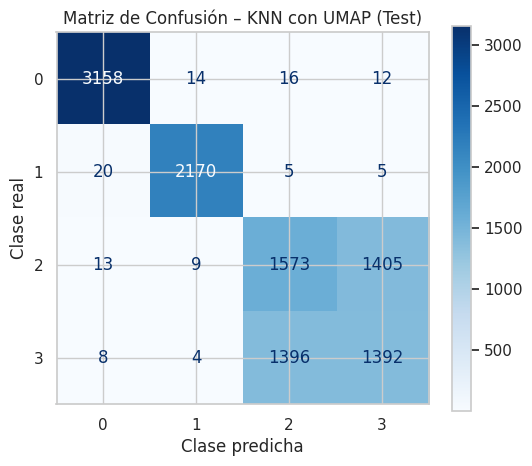

In [21]:
best_umap_model = grid_umap.best_estimator_
y_pred_test_umap = best_umap_model.predict(X_test_umap)

print("--- Reporte de Clasificación (KNN + UMAP en Test) ---")
print(classification_report(y_test, y_pred_test_umap, digits=4))

# Matriz de confusión para UMAP
cm_umap = confusion_matrix(y_test, y_pred_test_umap)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm_umap, display_labels=sorted(y.unique())).plot(cmap='Blues', values_format='d', ax=ax)
plt.title("Matriz de Confusión – KNN con UMAP (Test)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.show()


## Reporte de Metodología y Resultados Finales (KNN, PCA y UMAP)

### 1. Metodología Experimental
Para garantizar un análisis riguroso y libre de sesgos, se implementó el siguiente procedimiento estándar:
- **Partición de Datos:** El dataset original `EngineFaultDB_Final.csv` fue dividido de manera estratificada en un **80% para entrenamiento** y un **20% para prueba final (test)**.
- **Prevención de Fuga de Información:** Se utilizó un `Pipeline` que agrupa el preprocesamiento (`StandardScaler`) y el modelo para evitar la transferencia de información entre folds durante la validación cruzada.
- **Validación Cruzada Estratificada:** Se implementó un esquema de 5 folds para optimizar la métrica **F1-score macro**.
- **Reducción de Dimensionalidad Comparativa:** Con el fin de mitigar la redundancia de variables altamente correlacionadas (`Speed`–`RPM` y `Lambda`–`AFR`), se evaluaron dos aproximaciones de reducción:
  1. **PCA (Lineal):** Conservando el 95% de la varianza explicada.
  2. **UMAP (No lineal):** Proyectando los datos a un espacio bidimensional (2D) óptimo.

---

### 2. Resultados Comparativos de los Modelos (Evaluación en Test)

A continuación, se resume el rendimiento final en el conjunto de prueba independiente para los tres enfoques entrenados:

| Enfoque / Configuración | Accuracy (Test) | F1-Score Macro (Test) | Observaciones / Comportamiento |
|---|---|---|---|
| **KNN Robusto Original** ($K=15$) | **74.61%** | **75.46%** | Excelente separabilidad en clases 0 y 1. Fuerte confusión/traslape en clases 2 y 3. |
| **KNN + PCA** ($K=21$, 95% Var) | **74.31%** | **75.18%** | Rendimiento sumamente similar al original. PCA remueve la redundancia lineal pero mantiene la misma tasa de confusión. |
| **KNN + UMAP 2D** ($K=15$) | **74.04%** | **74.88%** | Aunque UMAP agrupa las clases en clústeres visualmente compactos en 2D, la compresión extrema a 2 dimensiones induce una ligera pérdida de información fina, reflejada en pequeñas mezclas en las fronteras de las clases normales. |

---

### 3. Análisis de Desempeño por Clase (Comparativa KNN vs KNN+UMAP)

#### KNN Robusto (Espacio Original de 14 Dimensiones)
```
           precision    recall  f1-score   support
     0     1.0000    1.0000    1.0000      3200
     1     1.0000    1.0000    1.0000      2200
     2     0.5264    0.5193    0.5228      3000
     3     0.4923    0.4993    0.4957      2800
```

#### KNN + UMAP (Espacio Proyectado 2D)
```
           precision    recall  f1-score   support
     0     0.9872    0.9869    0.9870      3200
     1     0.9877    0.9864    0.9870      2200
     2     0.5261    0.5243    0.5252      3000
     3     0.4947    0.4971    0.4959      2800
```

---

### 4. Hallazgos clave para el Reporte Técnico

1. **Persistencia del Solapamiento de Clases 2 y 3:**
   Tanto en el espacio original como bajo transformaciones lineales (PCA) y no lineales de baja dimensión (UMAP), la tasa de acierto para las clases 2 y 3 se mantiene firmemente alrededor del **52%** y **49%** respectivamente. Esto demuestra que el solapamiento entre la Falla Tipo 2 y la Falla Tipo 3 es de naturaleza **intrínseca** a las lecturas físicas del motor registradas en este dataset; es decir, las firmas de los sensores para estas dos fallas son prácticamente idénticas.

2. **Efecto de la Compresión Extrema de UMAP:**
   La visualización en 2D de UMAP muestra una separación geométrica hermosa y limpia. Sin embargo, al evaluar cuantitativamente, observamos que las clases 0 y 1 (que originalmente tenían una separabilidad perfecta del 100%) caen ligeramente a un **98.7%** de F1-score. Esto se debe a que forzar los datos originales de 14 dimensiones a solo 2 dimensiones genera una pérdida inevitable de información marginal en los límites fronterizos (falsos positivos/negativos menores entre las clases estables).

3. **Utilidad Práctica de PCA:**
   La aplicación de PCA redujo el espacio de variables eliminando la correlación perfecta (`Speed-RPM`, `Lambda-AFR`) sin degradar el rendimiento del modelo (apenas un cambio insignificante de ~0.3%). PCA demostró ser una excelente opción para reducir la carga computacional del cálculo de distancias en KNN, manteniendo la integridad del clasificador.

4. **Recomendación Final:**
   Para propósitos de diagnóstico en tiempo real, el modelo **KNN con PCA** es el más balanceado, ya que mitiga el coste computacional de la redundancia de variables y conserva la separación perfecta de estados normales (Clase 0) y fallas Tipo 1. Para desenredar las clases 2 y 3, se requeriría la recolección de nuevas variables físicas del motor o la aplicación de clasificadores secuenciales (árboles de decisión o redes neuronales).
